# Fitted window, forecast and truth for three signals

**Kernel:** `python3`, the default Python (3.10 or newer) with labfigs and `scipy` installed. Choose it before running.

**Shows:** one panel per signal. Left of the dashed line is the fitted window, drawn as a 95% band.
Right of it is the forecast, drawn as one faint line per draw. The black line is the truth.

**Graph type:** band, draws and truth over time (`lf.band`, `lf.paths`, `lf.truth`, `lf.split`).
The layout follows Fig. 3.11 of Hao's thesis.

**Writes:** `duffing_311.svg` next to this notebook.

**To tweak:** change the capitalised settings at the top of the **Figure** cell and re-run that cell.

**To save:** run the one-line cell under a figure. It writes one file for each type in `FORMATS`, set in the
Setup cell: `("svg",)` by default, `("svg", "pdf", "png")` for all three. Nothing is written until that cell runs.

**To run it all:** `jupyter nbconvert --to notebook --execute --inplace duffing_311.ipynb`, which also saves the figures in this notebook.

In [1]:
import numpy as np
from scipy.integrate import solve_ivp

import labfigs as lf

lf.use()
FORMATS = ("svg",)

## Data

Synthetic Duffing oscillator; no inference is run. Swap this cell for your own loading.
The figure only needs these arrays (all divided by the largest true value of their signal):

- `tau_obs`, `tau_new`, `tau_all`: time over the fitted window, the forecast window, and both
- `posterior`: fitted draws, shape `(signals, draws, len(tau_obs))`
- `forecast`: forecast draws, shape `(signals, draws, len(tau_new))`
- `truth`: true signals, shape `(signals, len(tau_all))`

In [2]:
DELTA, ALPHA, RHO, GAMMA, OMEGA = 0.3, -1.0, 1.0, 0.37, 1.2
T, N, DRAWS, SIGMA_Y = 30.0, 600, 100, 0.04
rng = np.random.default_rng(0)


def duffing(t, x, scale=1.0):
    return [x[1], scale * (-DELTA * x[1] - ALPHA * x[0] - RHO * x[0] ** 3) + GAMMA * np.cos(OMEGA * t)]


def smooth_noise(t, size):
    freq = rng.uniform(0.2, 1.5, (DRAWS, 4, 1))
    phase = rng.uniform(0, 2 * np.pi, (DRAWS, 4, 1))
    amp = rng.normal(size=(DRAWS, 4, 1))
    return size * (amp * np.sin(freq * t + phase)).sum(1) / 2


t_all = np.linspace(100, 100 + 2 * T, 2 * N - 1)
t_obs, t_new = t_all[:N], t_all[N - 1:]
true = solve_ivp(duffing, (0, t_all[-1]), [1.0, 0.0], t_eval=t_all, rtol=1e-9, atol=1e-9).y
true = np.vstack([true, true[0] + SIGMA_Y * rng.normal(size=t_all.size)])

widths = np.array([0.03, 0.09, 0.03])[:, None, None]
post = true[:, None, :N] + np.stack([smooth_noise(t_obs, 1.0) for _ in range(3)]) * widths
post[2] += SIGMA_Y * rng.normal(size=(DRAWS, N))

pred = np.empty((3, DRAWS, N))
for k in range(DRAWS):
    start = post[:2, k, -1]
    sol = solve_ivp(duffing, (t_new[0], t_new[-1]), start, t_eval=t_new, args=(1 + 0.03 * rng.normal(),), rtol=1e-8)
    pred[:2, k] = sol.y
    pred[2, k] = sol.y[0] + SIGMA_Y * rng.normal(size=N)

tau_obs, tau_new, tau_all = (t_obs - 100) / T, (t_new - 100) / T, (t_all - 100) / T
unit = np.abs(true).max(axis=1, keepdims=True)
posterior, forecast, truth = post / unit[:, None], pred / unit[:, None], true / unit

## Figure

Settings at the top of the cell:

- `NAME`: file name of the figure, without `.svg`
- `PANEL_ASPECT`: height of one panel divided by its width; raise it for taller panels
- `SIGNALS`: y label of each panel, top to bottom
- `X_LABEL`, `X_LIMITS`, `X_TICKS`: the shared time axis
- `Y_LIMITS`, `Y_TICKS`: the y axis of every panel; the spine stops at the outermost ticks
- `FIT_LABEL`, `FIT_COLOUR`: legend entry and colour of the band
- `FORECAST_LABEL`, `FORECAST_COLOUR`: legend entry and colour of the draws
- `LEVEL`: share of the fitted draws inside the band
- `FORECAST_STARTS`: where the dashed line goes on the x axis

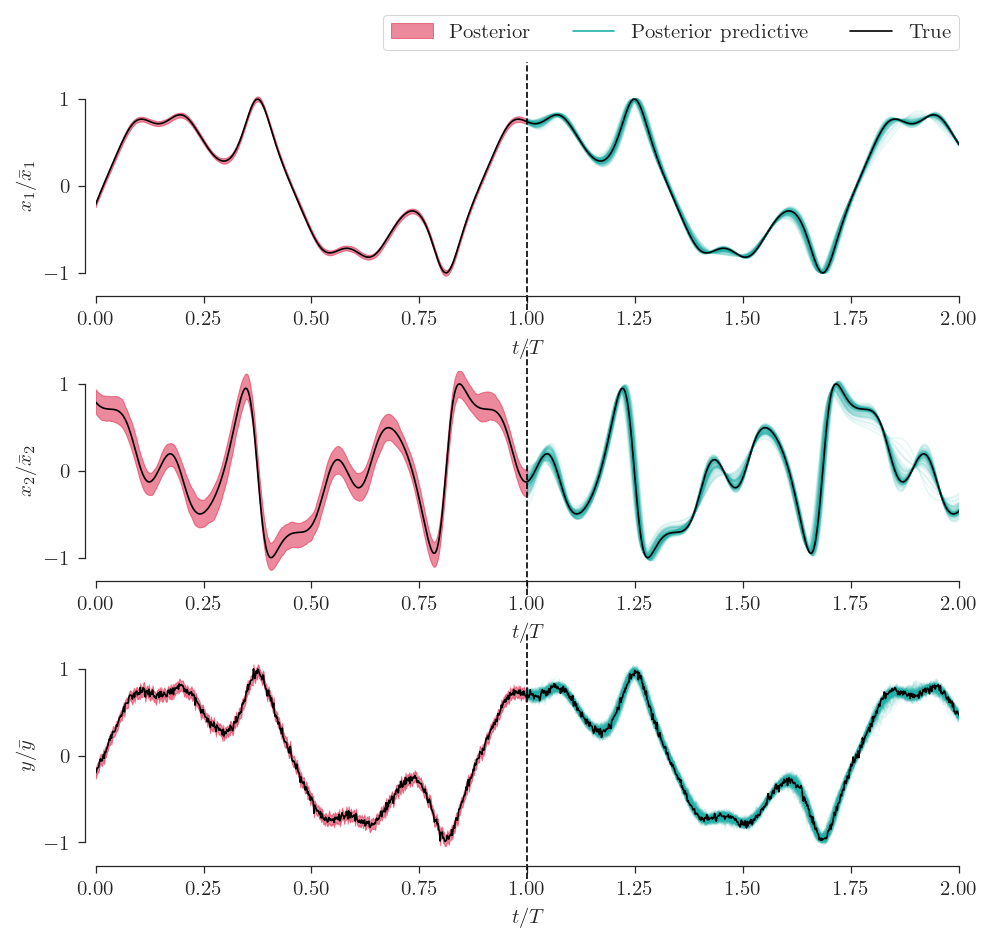

In [3]:
NAME = "duffing_311"
PANEL_ASPECT = 0.24
SIGNALS = [r"$x_1/\bar{x}_1$", r"$x_2/\bar{x}_2$", r"$y/\bar{y}$"]
X_LABEL, X_LIMITS, X_TICKS = r"$t/T$", (0, 2), np.arange(0, 2.01, 0.25)
Y_LIMITS, Y_TICKS = (-1.15, 1.15), [-1, 0, 1]
FIT_LABEL, FIT_COLOUR = "Posterior", lf.Colour.CRIMSON
FORECAST_LABEL, FORECAST_COLOUR = "Posterior predictive", lf.Colour.TEAL
LEVEL = 0.95
FORECAST_STARTS = 1.0

fig, axes = lf.subplots(len(SIGNALS), 1, aspect=PANEL_ASPECT)
for i, ax in enumerate(axes):
    lf.band(ax, tau_obs, posterior[i], level=LEVEL, color=FIT_COLOUR, label=FIT_LABEL)
    lf.paths(ax, tau_new, forecast[i], color=FORECAST_COLOUR, label=FORECAST_LABEL)
    lf.truth(ax, tau_all, truth[i])
    lf.split(ax, FORECAST_STARTS)
    ax.set(xlim=X_LIMITS, xticks=X_TICKS, ylim=Y_LIMITS, yticks=Y_TICKS, xlabel=X_LABEL, ylabel=SIGNALS[i])
lf.legend_above(axes[0])
lf.show(fig)

In [4]:
lf.save(fig, NAME, formats=FORMATS)

Saved duffing_311.svg
